# Model C, C2 (Oct 31, 2026) — EXPLORATORY

"Sit at the wall, try by a hazard, look, then keep or walk". `results/model_b_log.md`, entry 3: the spec, the decision rules, the yardstick and the implementation choices were committed there (e2ec1ec) before any number below. Code: `src/slider/model_c2.py` (data), `sim.py` motion / preset "C2", `tests/test_c2.py`.

**Spec (as given):**

> TASK: Model C, version C2 (EXPLORATORY). Fits on G-train only. Never load Ring/CT.
> New code path only: all old presets (L1, final, L1_M3, L0, APEM, B1, C1) stay
> bit-identical (fingerprint test). G-val stays untouched.
>
> FIRST: write log entry 3 (results/model_b_log.md) with this spec, its decision rules and
> the C yardstick (primary 1-4, secondary 5-7, descriptive 8-10). Commit it before
> computing anything.
>
> STEP 0 - CHECKS (G-train, human seats; each rule is fixed now)
> (a) Auto-repeat. Is the game keyboard-driven? Check the game code or docs in the repo /
>     OSF archive and report what you find. Then, per interface (lab v09, CC): the gap
>     between the FIRST own step of a movement that starts from rest (from the wall, or
>     after a mid-slider halt) and the next own step in the same direction. Histogram plus
>     quantiles.
>     RULE: if >= 40% of gaps lie within +/-0.05 s of a single value d in both interfaces,
>     it is apparatus: d_ar = d. Otherwise d_ar = 0.
> (b) Try hazard. Use 0.25 s bins at the wall, built exactly like the hazard table
>     (hazard.py bin rules). y = 1 if a try starts in the bin, where a try = the first step
>     off the wall of any excursion (reversal, probe or aborted excursion).
>     Fit two logistic models:
>       T0: A, e, r, lab;
>       T1: T0 + g = log(1 + time since any neighbor's last step).
>     RULE: include g iff its coefficient > 0, its 95% CI excludes 0, and the
>     likelihood-ratio test of T1 vs T0 gives p < 0.01. Report both fits and the verdict.
> (c) Walk timing. Per interface: q_w = per-tick chance that a player who is off the wall
>     and not committed takes its next step (geometric fit to the gaps between own steps
>     within probes and aborted excursions).
> (d) Keep rates per interface: P(kept | dA > 0, = 0, < 0) from pB2_try_keep.csv, set (i).
> (e) Pace. Per interface x round speed: the human band-to-band crossing pace (steps per
>     second, the 10a crossings).
> (f) Descriptive, humans vs C1 (5 C1 replicates, seed 7001, L5 design), per cell:
>     - share of round time with all 7 players at a wall;
>     - number of 6-1 and 5-2 standoffs per round;
>     - median standoff duration.
> Save the tables to results/tables/pC2_checks.csv. Report the verdicts of (a) and (b).
>
> STEP 1 - SIMULATOR, preset "C2" (per tick; same start and first trip as C1)
> - At the wall the player sits. The try hazard (T0 or T1 per the rule) is drawn per 0.25 s
>   bin, as in F2. A try = one step off the wall. M2' is NOT used.
> - After every own step (the try or a walk step), the player LOOKS:
>   dA = A just before its next decision point - A just before the step. The decision point
>   is the next tick; if d_ar > 0, it is after d_ar seconds.
>   KEEP with probability keep(sign(dA)) per interface. Keep = move continuously in the
>   direction of that last step, at a pace drawn per movement from (e), until reaching a
>   wall. Then sit there.
>   NOT KEPT = stay walking: the next step comes with chance q_w per tick, in a random
>   direction (50/50; toward the wall is blocked at the wall). Look again after each step.
> - Reaching any wall ends the walk, and the player sits.
> - Round end: the consensus rule or the time limit.
> - Tests:
>   - fingerprints;
>   - keep = 1 makes every try commit immediately;
>   - a walk that reaches the wall returns to sitting;
>   - the A look uses positions from before the decision point.
>
> STEP 2 - BUILD CHECKS (G6train design, R = 2, seed 573)
> - Try-hazard calibration: overall and by A decile (as C1).
> - Keep shares by sign(dA): recovered within their CIs.
> - q_w, and d_ar if > 0: recovered.
> - round_end agreement.
> If anything fails: diagnose and propose; don't change numbers.
>
> STEP 3 - RUN SCRIPTS
> - Register C2 (seed 8001) in p24_main.py and p24_checks.py: reported as EXPLORATORY with
>   the C yardstick, next to C1, L1 and final; no triggers.
> - Smoke-test with R = 2, delete the outputs, restore p24_checks.csv.
> - Commit. Report steps 0-3 and give the R = 200 command. Then stop.

In [1]:
import time

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from slider import config, design, model_b, model_c2, motion, sim
from slider import slider_logs as sl

pd.set_option("display.max_columns", 30)
pd.set_option("display.max_rows", 120)
pd.set_option("display.width", 220)

runs, table = sl.load_runs("behavior")              # G-train (G6train set): no G-val, Ring or CT
assert set(table["role"]) == {"train"}
checks = []                                         # rows of pC2_checks.csv


def add(check, interface, cell, stat, value, ci_lo=np.nan, ci_hi=np.nan, n=np.nan):
    checks.append({"check": check, "interface": interface, "cell": cell, "stat": stat, "value": value,
                   "ci_lo": ci_lo, "ci_hi": ci_hi, "n": n})

# Step 0 — checks

## (a) Auto-repeat

**What the repo and the OSF archive hold.**
- There is no game code. `data/raw/osf/Code` has only the Matlab model code (APEM, RW, GFRS; `SliderGame/*.m`). Its one "keyboard" hit is a commented-out Matlab `keyboard` debug call.
- The logs carry the game's settings and instructions:
  - Lab (EL / CL) instructions: "To move the slider back and forth, use the arrow keys on the keyboard."
  - Lab settings: "IncValue ... how much of the whole slider values it should moved with arrow keys" and "IndependentIncMode ... updates every 100 milliseconds".
  - Cloud (CC) instructions: "use the arrow keys on your keyboard".
- So both apparatus are keyboard-driven, with no mouse dragging described. The auto-repeat delay itself is a setting of the player's operating system, not of the game, and no log records it.

In [2]:
gaps = model_c2.first_step_gaps(runs)
counts = gaps.assign(used=gaps["gap"].notna()).groupby(["interface", "origin"]).agg(
    movements=("start", "size"), used=("used", "sum"),
    reversed=("left_out", lambda x: (x == "reversed").sum()), round_end=("left_out", lambda x: (x == "round_end").sum()))
used = gaps[gaps["gap"].notna()]
q = used.groupby(["interface", "origin"])["gap"].quantile([0.1, 0.25, 0.5, 0.75, 0.9]).unstack()
q_all = used.groupby("interface")["gap"].quantile([0.1, 0.25, 0.5, 0.75, 0.9]).unstack().assign(origin="all")
by = {i: used.loc[used["interface"] == i, "gap"].to_numpy() for i in ["lab_v09", "cc"]}
d_ar, d_star, low, own = model_c2.d_ar_rule(by)
near = pd.DataFrame({(i, o): {f"share within 0.05 of {d}": model_c2.share_near(x["gap"], d)[0] for d in [0.25, 0.5, d_star]}
                     for (i, o), x in used.groupby(["interface", "origin"])}).T
for (i, o), r in q.iterrows():
    for p, v in r.items():
        add("a", i, o, f"gap q{int(p * 100)}", v, n=counts.loc[(i, o), "used"])
for i, (d, sh) in own.items():
    add("a", i, "all", "own best d", d, n=len(by[i]))
    add("a", i, "all", "own best share", sh, n=len(by[i]))
add("a", "lab_v09+cc", "all", "d* (best common)", d_star)
add("a", "lab_v09+cc", "all", "min share at d*", low)
add("a", "lab_v09+cc", "all", "d_ar (rule)", d_ar)
display(counts)
display(pd.concat([q.reset_index(), q_all.reset_index()]).set_index(["interface", "origin"]).round(3))
display(near.round(3))
print(f"RULE: best common d* = {d_star:.2f} s, smallest share there = {low:.3f} (needs >= 0.40) -> d_ar = {d_ar}")
print("each interface's own best d:", {i: (d, round(s, 3)) for i, (d, s) in own.items()})

movements   used  reversed  round_end
interface origin                                       
cc        mid         20672  18008      2161        503
          wall         2591   2018       572          1
lab_v09   mid         15323  12920      2126        277
          wall         2287   1771       515          1

0.1   0.25    0.5   0.75    0.9
interface origin                                   
cc        mid     0.032  0.083  0.200  0.323  0.518
          wall    0.247  0.468  0.500  0.513  0.589
lab_v09   mid     0.100  0.200  0.300  0.500  0.700
          wall    0.200  0.400  0.500  0.500  0.600
cc        all     0.032  0.085  0.215  0.416  0.535
lab_v09   all     0.100  0.200  0.300  0.500  0.700

share within 0.05 of 0.25  share within 0.05 of 0.5
cc      mid                       0.234                     0.090
        wall                      0.103                     0.630
lab_v09 mid                       0.349                     0.168
        wall                      0.185                     0.551

RULE: best common d* = 0.25 s, smallest share there = 0.220 (needs >= 0.40) -> d_ar = 0.0
each interface's own best d: {'lab_v09': (0.25, 0.329), 'cc': (0.05, 0.286)}


**How to read it.**
- A movement from rest is a one-step own row after a halt: from the wall, or mid-slider (the first move included). The gap is the time to the next own step, used only if that step goes the same way.
- The rule pools both origins, as declared, and asks for one d holding >= 40% of the gaps in both interfaces.
- The third table splits the share near 0.25 s and 0.5 s by origin.

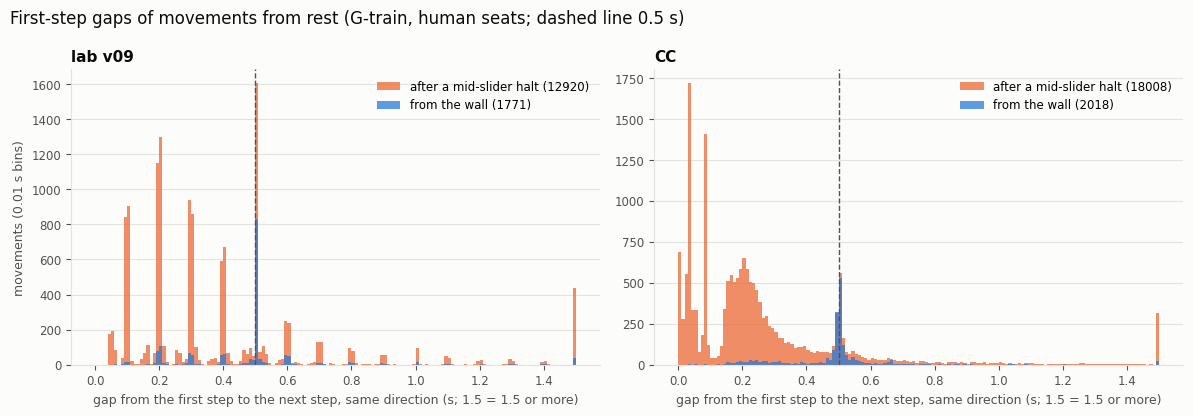

In [3]:
SURFACE, INK, INK_2, GRID = "#fcfcfb", "#0b0b0b", "#52514e", "#e4e3df"
COLORS = {"wall": "#2a78d6", "mid": "#eb6834"}
NAMES = {"lab_v09": "lab v09", "cc": "CC", "wall": "from the wall", "mid": "after a mid-slider halt"}
fig, axes = plt.subplots(1, 2, figsize=(12, 4.2), facecolor=SURFACE, sharey=False)
edges = np.arange(0, 1.51, 0.01)
for ax, iface in zip(axes, ["lab_v09", "cc"]):
    for origin in ["mid", "wall"]:
        x = used.loc[(used["interface"] == iface) & (used["origin"] == origin), "gap"]
        ax.hist(np.clip(x, 0, 1.5), bins=edges, color=COLORS[origin], alpha=0.75, label=f"{NAMES[origin]} ({len(x)})")
    ax.axvline(0.5, color=INK_2, linewidth=1, linestyle="--")
    ax.set_title(NAMES[iface], loc="left", fontsize=11, color=INK, fontweight="bold")
    ax.set_xlabel("gap from the first step to the next step, same direction (s; 1.5 = 1.5 or more)", color=INK_2, fontsize=9)
    ax.set_facecolor(SURFACE)
    ax.grid(axis="y", color=GRID, linewidth=0.8)
    ax.set_axisbelow(True)
    for side in ["top", "right"]:
        ax.spines[side].set_visible(False)
    for side in ["left", "bottom"]:
        ax.spines[side].set_color(GRID)
    ax.tick_params(colors=INK_2, labelsize=8.5)
    ax.legend(frameon=False, fontsize=8.5)
axes[0].set_ylabel("movements (0.01 s bins)", color=INK_2, fontsize=9)
fig.suptitle("First-step gaps of movements from rest (G-train, human seats; dashed line 0.5 s)", x=0.01, ha="left",
             fontsize=12, color=INK)
fig.tight_layout()
fig.savefig(config.FIGURES / "pC2_first_gaps.png", dpi=150, facecolor=SURFACE)
plt.show()

**How to read it.** The histograms overlay the two origins: blue starts from the wall, orange after a mid-slider halt. A spike at one gap that holds in both interfaces is what the rule calls apparatus.

## (b) Try hazard at the wall: T0 vs. T1

In [4]:
ht = pd.read_parquet(config.HAZARD_TABLE)
bins = model_c2.try_bins(runs, ht)                  # G-train rows only (split == "train"), at the wall
del ht
m0 = model_c2.fit_try(bins, model_c2.T0)
m1 = model_c2.fit_try(bins, model_c2.T0 + ["g"])
rule = model_c2.g_rule(m0, m1)
coefs = pd.concat([pd.DataFrame({"model": name, "term": m.params.index, "beta": m.params.to_numpy(),
                                 "se": m.bse.to_numpy(), "ci_lo": m.conf_int()[0].to_numpy(),
                                 "ci_hi": m.conf_int()[1].to_numpy()}) for name, m in [("T0", m0), ("T1", m1)]])
coefs.to_csv(config.PC2_TRY, index=False)
for r in coefs.itertuples():
    add("b", "all", r.model, f"beta {r.term}", r.beta, r.ci_lo, r.ci_hi, n=len(bins))
add("b", "all", "T1 vs T0", "LR", rule["lr"], n=len(bins))
add("b", "all", "T1 vs T0", "p", rule["p"], n=len(bins))
add("b", "all", "rule", "include g", float(rule["include_g"]))
print(bins.groupby("interface")["y_try"].agg(bins="size", tries="sum", rate="mean").round(4))
print(f"ll T0 {m0.llf:.1f}, T1 {m1.llf:.1f}; converged {m0.mle_retvals['converged']}, {m1.mle_retvals['converged']}")
print(f"RULE: beta_g = {rule['beta_g']:.4f} [{rule['ci_lo']:.4f}, {rule['ci_hi']:.4f}], LR = {rule['lr']:.2f}, "
      f"p = {rule['p']:.2g} -> include g: {rule['include_g']} (C2 uses {'T1' if rule['include_g'] else 'T0'})")
coefs.pivot(index="term", columns="model", values=["beta", "ci_lo", "ci_hi"]).swaplevel(axis=1).sort_index(axis=1).round(4)

             bins  tries    rate
interface                       
cc         124574   2555  0.0205
lab_v09    107224   2317  0.0216
old_cl      19863    372  0.0187
ll T0 -23138.5, T1 -23119.6; converged True, True
RULE: beta_g = 0.0879 [0.0604, 0.1154], LR = 37.79, p = 7.9e-10 -> include g: True (C2 uses T1)


model                     T0                      T1                
                        beta   ci_hi   ci_lo    beta   ci_hi   ci_lo
term                                                                
A                    -2.1295 -2.0386 -2.2204 -2.2217 -2.1268 -2.3166
const                -1.6645 -1.5729 -1.7562 -1.6718 -1.5805 -1.7632
g                        NaN     NaN     NaN  0.0879  0.1154  0.0604
lab                   0.2398  0.2971  0.1825  0.2573  0.3148  0.1997
time_at_end_log1p    -0.2714 -0.1923 -0.3505 -0.2681 -0.1889 -0.3473
time_since_rev_log1p -0.1992 -0.1055 -0.2930 -0.2158 -0.1218 -0.3098

**How to read it.**
- Bins are the hazard table's G-train bins at the wall (abs_s = 1); y = 1 when the seat's first step off the wall falls in the bin.
- T0 has M2'-like terms without |s| and at_end, which are constant at the wall. T1 adds g = log(1 + time since a neighbor's last step).
- The rule needs all three: beta_g > 0, a Wald CI above 0, and the LR test at p < 0.01.

## (c) Walk timing q_w, (d) keep rates, (e) pace

In [5]:
walk = model_c2.walk_gaps(runs, d_ar)
qw = []
for name in motion.INTERFACES:
    w = walk[walk["interface"] == name]
    lo, hi = model_b.boot_groups(w, lambda x: np.array([model_c2.q_w(x)]), n_boot=1000, seed=config.SEED)
    qw.append({"interface": name, "gaps": len(w), "files": w["file"].nunique(), "q_w": model_c2.q_w(w),
               "ci_lo": lo[0], "ci_hi": hi[0], "median_ticks": w["n"].median()})
    add("c", name, "all", "q_w", qw[-1]["q_w"], lo[0], hi[0], n=len(w))
qw = pd.DataFrame(qw).set_index("interface")
qw.round(4)

,gaps,files,q_w,ci_lo,ci_hi,median_ticks
interface,,,,,,
lab_v09,8329,20,0.2322,0.1958,0.2848,2.0
old_cl,6881,2,0.4504,0.4488,0.4622,1.0
cc,5849,17,0.0862,0.0704,0.1065,6.0


**How to read it.** q_w is the per-tick chance of the next walk step after the decision point, fitted to every gap between own steps inside excursions that come back to their wall. The decision point is the next tick, since d_ar = 0. Old CL rests on 2 files, so its CI is a two-group bootstrap.

In [6]:
tk = pd.read_csv(config.PB2_TRY_KEEP)
tk = tk[(tk["topology"] == "all") & (tk["section"] == "(i) all tries")]
SIGNS = {"P(kept | dA > 0)": "keep_pos", "P(kept | dA = 0)": "keep_zero", "P(kept | dA < 0)": "keep_neg"}
keep = tk[tk["cell"].isin(list(SIGNS))].assign(parameter=lambda x: x["cell"].map(SIGNS))
for r in keep.itertuples():
    add("d", r.interface, "all", r.parameter, r.estimate, r.ci_low, r.ci_high, n=r.n)
keep.pivot(index="interface", columns="parameter", values="estimate").loc[motion.INTERFACES, list(SIGNS.values())].round(3)

parameter,keep_pos,keep_zero,keep_neg
interface,,,
lab_v09,0.862,0.811,0.737
old_cl,0.894,0.786,0.744
cc,0.886,0.819,0.710


**How to read it.** These are the B2 keep rates (`pB2_try_keep.csv`, set (i), all topologies), used as stored: P(kept) for tries after which A rose, stayed the same, or fell.

In [7]:
pace = model_c2.paces(runs)
pace[["interface", "round_speed", "file", "duration", "v", "f"]].to_parquet(config.PC2_PACE, index=False)
pt = pace.groupby(["interface", "round_speed"]).agg(
    crossings=("v", "size"), v_q25=("v", lambda x: x.quantile(0.25)), v_median=("v", "median"),
    v_q75=("v", lambda x: x.quantile(0.75)), f_q25=("f", lambda x: x.quantile(0.25)), f_median=("f", "median"),
    f_q75=("f", lambda x: x.quantile(0.75)), f_above_1=("f", lambda x: (x > 1).mean()))
for (i, sp), r in pt.iterrows():
    for stat in ["v_median", "f_median", "f_q25", "f_q75"]:
        add("e", i, f"speed {sp:.2f}", stat, r[stat], n=r["crossings"])
pt.round(3)

crossings  v_q25  v_median  v_q75  f_q25  f_median  f_q75  f_above_1
interface round_speed                                                                      
cc        2.94               137  1.389     3.009  3.220  0.472     1.023  1.095      0.584
          3.03              1091  1.046     2.957  3.036  0.345     0.976  1.002      0.382
          3.23                97  1.085     2.988  3.327  0.336     0.925  1.030      0.320
          3.33               299  0.865     3.004  3.291  0.260     0.902  0.988      0.207
lab_v09   0.50                67  0.382     0.567  0.997  0.763     1.133  1.994      0.627
          1.00              1104  0.486     0.944  1.000  0.486     0.944  1.000      0.230
          2.00                24  1.000     1.910  1.932  0.500     0.955  0.966      0.042
old_cl    0.20                87  0.162     0.195  0.200  0.810     0.977  1.000      0.161

**How to read it.**
- Pace is per 10a crossing (end band to end band, complete, no jump, raw rows): v in units/s, and f = v / round speed, which is steps per tick.
- C2 draws f for each kept movement from the same interface and round speed, capped at 1.
- f > 1 means the logged crossing ran faster than the round's estimated speed.

## (f) Descriptive: humans vs. C1 (R = 5, seed 7001, L5 design)

In [8]:
hum_runs, _ = sl.load_runs("behavior", keep_bot=False, keep_incomplete=False)     # G-train, as L5
d5 = design.design("L5")
c1_runs, _ = design.simulate_design(d5, "C1", R=5, seed=7001)
desc = pd.concat({"human": model_c2.descriptive(hum_runs), "C1": model_c2.descriptive(c1_runs)}, axis=1).swaplevel(axis=1)
cols = ["rounds", "all_wall_share", "standoffs_6-1_per_round", "standoffs_5-2_per_round", "median_duration_6-1",
        "median_duration_5-2", "median_duration_all"]
desc = desc[[(c, w) for c in cols for w in ["human", "C1"]]]
for (top, ds), r in desc.iterrows():
    for (stat, who), v in r.items():
        add("f", who, f"{top} {ds}", stat, v)
desc.round(3)

rounds      all_wall_share        standoffs_6-1_per_round        standoffs_5-2_per_round        median_duration_6-1        median_duration_5-2        median_duration_all       
                   human   C1          human     C1                   human     C1                   human     C1               human     C1               human     C1               human     C1
topology  dataset                                                                                                                                                                                 
Full      CC          31  180          0.120  0.199                   1.548  2.211                   0.613  3.994               2.640  2.608               1.302  1.518               1.912  1.871
          CL          33  270          0.039  0.049                   0.667  1.222                   0.182  1.637               2.300  2.800               0.750  1.600               2.250  2.000
Hierarchy CC          34  200          0.224  0.291                   0.912  1.530                   0.912  2.230               3.628  2.277               0.919  1.419               1.535  1.682
          CL          33  265          0.048  0.100                   0.394  1.155                   0.273  1.540               0.900  2.200               0.700  1.400               0.800  1.700
          EL          33  255          0.113  0.155                   0.424  1.259                   0.545  1.651               1.800  2.600               0.700  1.500               0.900  1.800
Star      CC          33  195          0.065  0.168                   0.515  1.077                   0.152  1.226               2.192  2.541               2.529  1.716               2.361  2.079

**How to read it.** Per cell, humans (G-train, bot-free, complete rounds) vs. C1 (R = 5 on the L5 design):
- the share of round time with all 7 seats at a wall;
- standoffs per round (all 7 at a wall, split 6-1 or 5-2, >= 0.5 s);
- the median standoff duration (start to break or round end).

Descriptive only.

In [9]:
params = [{"interface": "all", "parameter": "d_ar", "estimate": d_ar, "ci_lo": np.nan, "ci_hi": np.nan},
          {"interface": "all", "parameter": "use_g", "estimate": float(rule["include_g"]), "ci_lo": np.nan, "ci_hi": np.nan}]
params += [{"interface": i, "parameter": "q_w", "estimate": r["q_w"], "ci_lo": r["ci_lo"], "ci_hi": r["ci_hi"]}
           for i, r in qw.iterrows()]
params += [{"interface": r.interface, "parameter": r.parameter, "estimate": r.estimate, "ci_lo": r.ci_low,
            "ci_hi": r.ci_high} for r in keep.itertuples()]
params = pd.DataFrame(params)
params.to_csv(config.PC2_PARAMS, index=False)
pd.DataFrame(checks).to_csv(config.PC2_CHECKS, index=False)
print(f"VERDICTS: (a) d_ar = {d_ar} | (b) include g = {rule['include_g']} -> C2 uses {'T1' if rule['include_g'] else 'T0'}")
params.round(4)

VERDICTS: (a) d_ar = 0.0 | (b) include g = True -> C2 uses T1


,interface,parameter,estimate,ci_lo,ci_hi
0,all,d_ar,0.0000,NaN,NaN
1,all,use_g,1.0000,NaN,NaN
2,lab_v09,q_w,0.2322,0.1958,0.2848
3,old_cl,q_w,0.4504,0.4488,0.4622
4,cc,q_w,0.0862,0.0704,0.1065
5,lab_v09,keep_pos,0.8623,0.8108,0.9050
6,lab_v09,keep_zero,0.8110,0.7152,0.8971
7,lab_v09,keep_neg,0.7369,0.6956,0.7808
8,old_cl,keep_pos,0.8944,0.8899,0.9091
9,old_cl,keep_zero,0.7857,0.7500,0.7917


**How to read it.** These are the simulator's inputs (`pC2_params.csv`): d_ar, which try model to use, q_w per interface, and keep by sign(dA). The T0 / T1 coefficients are in `pC2_try_hazard.csv` and the paces in `pC2_pace.parquet`. Every step-0 table is in `pC2_checks.csv`.

# Step 2 — build checks: C2 on G6train, R = 2, seed 573 (the simulator trace kept per round)

In [10]:
G6 = design.design("G6train")
model = sim.preset("C2")
print("try rule:", model["rule"].model)
streams = np.random.SeedSequence(573).spawn(len(G6))           # design.simulate_rounds' streams
start = time.time()
rounds, sbins, looks = [], [], []
for row, stream in zip(G6.itertuples(), streams):
    sim_seed, log_seed = stream.spawn(2)
    A = row.graph[np.ix_(row.seat_node, row.seat_node)]
    trace = []
    out = sim.simulate(A, row.T, row.interface, R=2, seed=sim_seed, speed=row.speed, trace=trace, **model)
    rounds.append((out, np.random.default_rng(log_seed)))
    b = pd.concat([d for d in trace if "tau" in d], ignore_index=True)
    fires = [d for d in trace if "fire" in d]
    b["fired"] = False
    if fires:
        f = pd.concat(fires, ignore_index=True)
        for x in f.itertuples():                                  # the bin the try is dated in
            k = b.index[(b["rep"] == x.rep) & (b["player"] == x.player) & (b["tau"] <= x.fire + 1e-6)][-1]
            b.loc[k, "fired"] = True
    end = np.array([o["end_time"] for o in out])
    b = b[b["risk"] & (b["tau"] + sim.BIN + 0.1 <= end[b["rep"]])]
    sbins.append(b[["rep", "player", "tau", "h", "A", "fired"]].assign(interface=row.interface, round_id=row.round_id))
    lk = [d for d in trace if "look" in d]
    if lk:
        looks.append(pd.concat(lk, ignore_index=True).assign(interface=row.interface))
sbins, looks = pd.concat(sbins, ignore_index=True), pd.concat(looks, ignore_index=True)
check = design.simulate_rounds(G6.head(3), "C2", R=2, seed=573)    # the traced rounds are design.simulate_rounds'
assert all(a["events"].equals(b["events"]) for (x, _), (y, _) in zip(rounds[:3], check) for a, b in zip(x, y))
sim_runs = [run for r in range(2) for run in design.copy_runs(G6, rounds, r, 573)]
print(len(sim_runs), "rounds |", f"{(time.time() - start) / 60:.1f} min")

try rule: T1


488 rounds | 6.4 min


### Try-hazard calibration: at-risk at-wall bins, observed tries vs. the sum of h (+/- 3%)

In [11]:
from scipy import stats


def calib(d):
    exp, obs = d["h"].sum(), d["fired"].sum()
    se = np.sqrt((d["h"] * (1 - d["h"])).sum())
    return pd.Series({"bins": len(d), "expected": exp, "observed": obs, "rel_diff": obs / exp - 1, "rel_se": se / exp,
                      "pass": abs(obs / exp - 1) <= 0.03})


sbins["A_decile"] = pd.qcut(sbins["A"].rank(method="first"), 10, labels=range(1, 11))
overall = pd.concat([sbins.groupby("interface")[["h", "fired"]].apply(calib).loc[motion.INTERFACES],
                     calib(sbins).to_frame("pooled").T])
deciles = sbins.groupby("A_decile", observed=True)[["h", "fired"]].apply(calib)
deciles["A_range"] = sbins.groupby("A_decile", observed=True)["A"].agg(lambda a: f"[{a.min():.2f}, {a.max():.2f}]")
z = deciles["rel_diff"] / deciles["rel_se"]
print(f"by decile: chi-square {np.sum(z ** 2):.2f} on 10 df, p = {stats.chi2.sf(np.sum(z ** 2), 10):.3f}")
display(overall.round(4))
deciles.round(4)

by decile: chi-square 13.65 on 10 df, p = 0.189


,bins,expected,observed,rel_diff,rel_se,pass
lab_v09,404631,14461.183677,14284,-0.012252,0.008043,True
old_cl,62042,2009.765638,2041,0.015541,0.021734,True
cc,383261,11242.748233,11296,0.004737,0.009172,True
pooled,849934,27713.697547,27621,-0.003345,0.005826,True


,bins,expected,observed,rel_diff,rel_se,pass,A_range
A_decile,,,,,,,
1,84994,6947.5918,6887,-0.0087,0.0114,True,"[0.00, 0.07]"
2,84993,5353.4388,5378,0.0046,0.0132,True,"[0.07, 0.19]"
3,84993,4150.1427,4201,0.0123,0.0151,True,"[0.19, 0.31]"
4,84994,3326.8677,3361,0.0103,0.0169,True,"[0.31, 0.43]"
5,84993,2528.6886,2557,0.0112,0.0195,True,"[0.43, 0.50]"
6,84993,1873.4624,1835,-0.0205,0.0228,True,"[0.50, 0.67]"
7,84994,1274.3783,1198,-0.0599,0.0278,False,"[0.67, 0.83]"
8,84993,815.3488,796,-0.0237,0.0348,True,"[0.83, 1.00]"
9,84993,764.0806,704,-0.0786,0.0360,False,"[1.00, 1.00]"


**How to read it.** Every complete at-risk bin of the simulation is traced. Observed tries are compared with the sum of h, per interface and pooled, and by decile of A (pooled). PASS means within ±3%; `rel_se` is the binomial SE of the relative difference.

### Keep shares by sign(dA)

In [12]:
SIGN = {"keep_pos": "> 0", "keep_zero": "= 0", "keep_neg": "< 0"}
sim_tries = model_b.try_table(sim_runs)
sim_tries["sign"] = model_b.sign_label(sim_tries["dA"].to_numpy())
k = keep.assign(sign=keep["parameter"].map(SIGN)).set_index(["interface", "sign"])[["estimate", "ci_low", "ci_high"]]
got = sim_tries.groupby(["interface", "sign"])["kept"].agg(sim_tries="size", sim_P_kept="mean")
kr = k.join(got)
kr["pass"] = (kr["sim_P_kept"] >= kr["ci_low"]) & (kr["sim_P_kept"] <= kr["ci_high"])
looks["sign"] = model_b.sign_label(looks["dA"].to_numpy())
impl = looks.groupby(["interface", "sign"])["kept"].agg(looks="size", kept_share="mean")
kr = kr.join(impl)
kr.loc[motion.INTERFACES].round(3)

estimate  ci_low  ci_high  sim_tries  sim_P_kept   pass   looks  kept_share
interface sign                                                                             
lab_v09   > 0      0.862   0.811    0.905     4776.0       0.905  False  4885.0       0.867
          = 0      0.811   0.715    0.897     2423.0       0.936  False  2883.0       0.822
          < 0      0.737   0.696    0.781     7271.0       0.873  False  8426.0       0.732
old_cl    > 0      0.894   0.890    0.909      605.0       1.000  False   615.0       0.907
          = 0      0.786   0.750    0.792      299.0       0.993  False   455.0       0.791
          < 0      0.744   0.711    0.870      901.0       0.996  False  1242.0       0.737
cc        > 0      0.886   0.870    0.901     4543.0       0.920  False  4448.0       0.883
          = 0      0.819   0.764    0.874      981.0       0.902  False  1401.0       0.832
          < 0      0.710   0.672    0.752     5942.0       0.881  False  6992.0       0.721

**How to read it.**
- **The check** (`sim_P_kept`): the B2 code (`model_b.try_table`, set (i)) on the simulated logs, compared with the human pB2 CI. A try counts as kept if the detector sees a reversal (2 steps against the direction), with dA read from the logged rows.
- **The implementation check** (`kept_share`): the share of the simulator's own looks that kept, by its own sign(dA), against keep(sign) (`estimate`).

### q_w and d_ar recovered

In [13]:
sim_walk = model_c2.walk_gaps(sim_runs, d_ar)
qr = qw[["q_w", "ci_lo", "ci_hi"]].copy()
qr["sim_gaps"] = sim_walk.groupby("interface").size()
qr["re_estimate"] = [model_c2.q_w(sim_walk[sim_walk["interface"] == i]) for i in qr.index]
qr["pass"] = (qr["re_estimate"] >= qr["ci_lo"]) & (qr["re_estimate"] <= qr["ci_hi"])
print("d_ar = 0: no auto-repeat in C2, so there is no d_ar to recover")
qr.round(4)

d_ar = 0: no auto-repeat in C2, so there is no d_ar to recover


,q_w,ci_lo,ci_hi,sim_gaps,re_estimate,pass
interface,,,,,,
lab_v09,0.2322,0.1958,0.2848,2035,0.2521,True
old_cl,0.4504,0.4488,0.4622,299,0.4746,False
cc,0.0862,0.0704,0.1065,1642,0.0969,True


**How to read it.** The step-0 (c) code is run on the simulated logs: gaps between own steps inside excursions that return to their wall. The re-estimate is compared with the human 95% CI.

### Round end

In [14]:
from slider import fraught
outs = [rounds[i][0][r] for r in range(2) for i in range(len(G6))]          # sim_runs' order: copy, then round
diff = np.array([abs(fraught.round_end(run["t"], run["end"], run["session"]) - o["end_time"]) - o["dt"]
                 for run, o in zip(sim_runs, outs)])
same = all(sim.consensus(run["X"][-1]) == o["success"] for run, o in zip(sim_runs, outs))
print(f"{len(sim_runs)} rounds: |round_end - simulator end| <= dt in {np.sum(diff <= 1e-9)}; "
      f"consensus at the last row <=> success: {same}")

488 rounds: |round_end - simulator end| <= dt in 488; consensus at the last row <=> success: True


**How to read it.** fraught.round_end reads each simulated log back. It must agree with the simulator's own end time within one tick, and the last logged row must be a consensus exactly when the round succeeded. `tests/test_c2.py` runs the same test.

## Diagnosis of the misses (no number changed; proposals in the log)

**Keep (the data check fails in all 9 cells; the implementation check matches keep in all 9).** B2's "kept" is the detector's reversal: 2 steps of k against the direction. That is not C2's keep.
- After a try that is NOT kept, C2's next walk step goes away from the wall half the time. The detector then sees 2 steps away and calls the try a reversal.
- So on the 0.1 grid the B2 measure of a C2 player is about keep + (1 - keep) / 2. This is approximate: the next look can still keep a run back to the wall.
- On old CL, a try is one 0.02 step, which does not change k = round(10 s). The detector first sees the excursion several steps later, by which point it is nearly always a kept run, so P(kept) is close to 1.

In [15]:
diag = kr[["estimate", "sim_P_kept", "kept_share"]].copy()
diag["implementation z"] = (kr["kept_share"] - kr["estimate"]) / np.sqrt(kr["estimate"] * (1 - kr["estimate"]) / kr["looks"])
diag["keep + (1 - keep) / 2"] = diag["estimate"] + (1 - diag["estimate"]) / 2
diag["keep giving the human B2 value: 2 P - 1"] = 2 * diag["estimate"] - 1
diag.loc[motion.INTERFACES].round(3)

estimate  sim_P_kept  kept_share  implementation z  keep + (1 - keep) / 2  keep giving the human B2 value: 2 P - 1
interface sign                                                                                                                    
lab_v09   > 0      0.862       0.905       0.867             1.027                  0.931                                    0.725
          = 0      0.811       0.936       0.822             1.516                  0.906                                    0.622
          < 0      0.737       0.873       0.732            -1.092                  0.868                                    0.474
old_cl    > 0      0.894       1.000       0.907             1.045                  0.947                                    0.789
          = 0      0.786       0.993       0.791             0.286                  0.893                                    0.571
          < 0      0.744       0.996       0.737            -0.603                  0.872                                    0.488
cc        > 0      0.886       0.920       0.883            -0.598                  0.943                                    0.772
          = 0      0.819       0.902       0.832             1.209                  0.910                                    0.638
          < 0      0.710       0.881       0.721             2.094                  0.855                                    0.420

**q_w (old CL misses; lab v09 and CC pass but sit above the human value).** The (c) estimator treats every gap inside an excursion that returns to its wall as a walk gap. In C2 such an excursion can end with a KEPT run back to the wall (a walk step toward the wall, then a look that keeps). Those 1-tick steps (f is about 1) push the re-estimate up.

The check below compares the share of 1-tick gaps with q_w, which is what a pure walk with D = 1 gives. Old CL's human CI comes from 2 groups, so it is nearly a point; the miss is 0.475 vs. [0.449, 0.462].

In [16]:
one = pd.DataFrame({"q_w": qw["q_w"], "human share n = 1": walk.groupby("interface")["n"].apply(lambda n: (n == 1).mean()),
                    "sim share n = 1": sim_walk.groupby("interface")["n"].apply(lambda n: (n == 1).mean()),
                    "sim re-estimate": qr["re_estimate"]})
one.loc[motion.INTERFACES].round(3)

,q_w,human share n = 1,sim share n = 1,sim re-estimate
interface,,,,
lab_v09,0.232,0.395,0.298,0.252
old_cl,0.450,0.717,0.505,0.475
cc,0.086,0.312,0.166,0.097
